### Funktionen: Graphen, Nullstellen, Scheitel, Wachstum, Sinus - Übungen

In diesem Notebook untersuchst du **Funktionen** mit sympy: Funktionswerte und Wertetabellen, Graphen, lineare und quadratische
Funktionen, Potenz-, Wurzel- und Exponentialfunktionen, ganzrationale Funktionen und die Sinusfunktion. Du bestimmst Nullstellen,
Scheitelpunkte, Schnittpunkte, Symmetrie und das Verhalten für große x.

Vorausgesetzt werden die Notebooks *Zahlen exakt*, *Terme* und *Gleichungen*.

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Danach folgen viele kleine Übungen. Unter den meisten Aufgaben steht das **erwartete Ergebnis**, bei Graphen als Bild.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ gibt es keine Lösung zum Aufklappen: Dort führst du einfach die Zelle aus und vergleichst.

#### sympy laden

**Führe diese Zelle zuerst aus** (und nach jedem Neustart des Kernels wieder). Sie lädt sympy, schaltet die Formel-Ausgabe ein,
lädt matplotlib für die Graphen und legt die Variablen `x`, `y`, `a`, `b` und `c` an.

In [ ]:
from sympy import *
init_printing()
import matplotlib.pyplot as plt
x, y, a, b, c = symbols('x y a b c')

## 1. Funktionen und Funktionswerte

#### Eine Funktion als Python-Funktion

Eine Funktion wie f(x) = x² − 3x schreibt man in Python mit `def`:

```python
def f(x):
    return x**2 - 3*x
```

Dann ist `f(2)` der Funktionswert an der Stelle 2 und `f(x)` der Funktionsterm. Mit `f(a + 1)` setzt man auch Terme ein.
Steht im Term eine **Division**, setze Zahlen als `Integer(...)` oder `Rational(...)` ein, sonst rechnet Python mit Kommazahlen:
Für f(x) = 1/x ist `f(2)` die Kommazahl 0.5, `f(Integer(2))` der Bruch 1/2.
Eine **Wertetabelle** erstellt man mit einer List Comprehension.

In [ ]:
def f(x):
    return x**2 - 3*x

display(f(2))
display(f(Rational(1, 2)))
display(f(x))
display(expand(f(a + 1)))
[(k, f(k)) for k in range(-1, 5)]

#### Aufgabe 1.1

Definiere `f(x) = 2x² − 5` und gib `f(3)` und `f(−1/2)` aus.

**Erwartete Ausgabe:**

$\displaystyle 13$

$\displaystyle - \frac{9}{2}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def f(x):
    return 2*x**2 - 5

display(f(3))
f(Rational(-1, 2))
```

</details>

#### Aufgabe 1.2

Erstelle für `g(x) = x³ − 2x` eine Wertetabelle als Liste von Paaren für die ganzen Zahlen von −2 bis 2.

**Erwartete Ausgabe:**

$\displaystyle \left[ \left( -2, \  -4\right), \  \left( -1, \  1\right), \  \left( 0, \  0\right), \  \left( 1, \  -1\right), \  \left( 2, \  4\right)\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def g(x):
    return x**3 - 2*x

[(k, g(k)) for k in range(-2, 3)]
```

</details>

#### Aufgabe 1.3

Definiere `h(x) = (x + 1)/(x − 2)` und gib `h(0)` und `h(3)` exakt (mit `Integer`) sowie `h(√2)` (mit `radsimp()`) aus.

**Erwartete Ausgabe:**

$\displaystyle - \frac{1}{2}$

$\displaystyle 4$

$\displaystyle \frac{- 3 \sqrt{2} - 4}{2}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def h(x):
    return (x + 1) / (x - 2)

display(h(Integer(0)), h(Integer(3)))
radsimp(h(sqrt(2)))
```

</details>

#### Aufgabe 1.4

Für `f(x) = x² + 1`: Gib `f(a + b)` ausmultipliziert aus.

**Erwartete Ausgabe:**

$\displaystyle a^{2} + 2 a b + b^{2} + 1$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def f(x):
    return x**2 + 1

expand(f(a + b))
```

</details>

#### Aufgabe 1.5

Für `f(x) = 3x − 4`: Gib `f(f(x))` vereinfacht aus.

**Erwartete Ausgabe:**

$\displaystyle 9 x - 16$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def f(x):
    return 3*x - 4

expand(f(f(x)))
```

</details>

#### Aufgabe 1.6

Für `f(x) = x²`: Gib den Differenzenquotienten `(f(x + h) − f(x))/h` vereinfacht aus.

**Erwartete Ausgabe:**

$\displaystyle h + 2 x$

In [ ]:
h = symbols('h')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
h = symbols('h')
def f(x):
    return x**2

simplify((f(x + h) - f(x)) / h)
```

</details>

## 2. Graphen zeichnen

#### `plot()`

`plot(term, (x, von, bis))` zeichnet den Graphen. Schreibe ein **Semikolon** `;` ans Ende der Zeile, sonst gibt Jupyter unter dem Bild
noch eine unschöne Textzeile aus.

- Mehrere Graphen: `plot(term1, term2, (x, -3, 3))`, mit `legend=True` erscheint eine Legende.
- `ylim=(-5, 5)` legt den Bereich der y-Achse fest, `title='...'` setzt eine Überschrift.
- Die Achsen schneiden sich wie im Heft im Ursprung.

In [ ]:
plot(x**2 - 2, (x, -3, 3));

#### Mehrere Graphen

In [ ]:
plot(x**2, 2*x**2, x**2 / 2, (x, -2, 2), legend=True, title='Parabeln');

#### Aufgabe 2.1

Zeichne den Graphen von `f(x) = x² − 4x + 3` für x von −1 bis 5.

**Erwartete Ausgabe:**



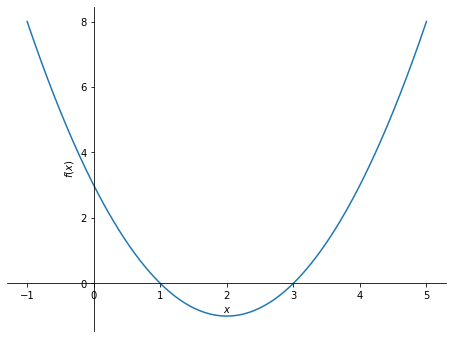

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
plot(x**2 - 4*x + 3, (x, -1, 5));
```

</details>

#### Aufgabe 2.2

Zeichne die Graphen von `2x − 1` und `−x + 5` für x von −2 bis 4 mit Legende.

**Erwartete Ausgabe:**



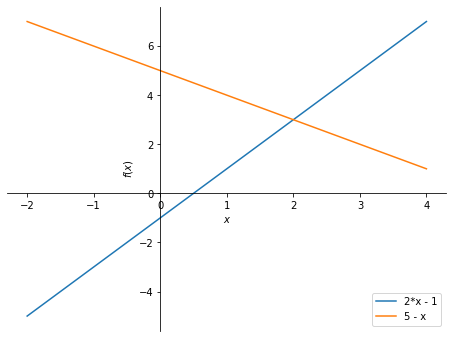

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
plot(2*x - 1, -x + 5, (x, -2, 4), legend=True);
```

</details>

#### Aufgabe 2.3

Zeichne den Graphen von `1/x` für x von −4 bis 4 mit der y-Achse von −5 bis 5.

**Erwartete Ausgabe:**



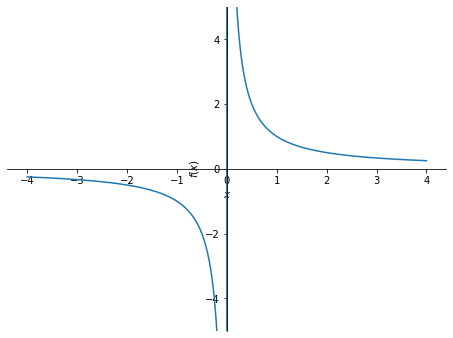

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
plot(1 / x, (x, -4, 4), ylim=(-5, 5));
```

</details>

#### Aufgabe 2.4

Zeichne `x³ − 3x` für x von −2,5 bis 2,5 mit der Überschrift `f(x) = x³ − 3x`.

**Erwartete Ausgabe:**



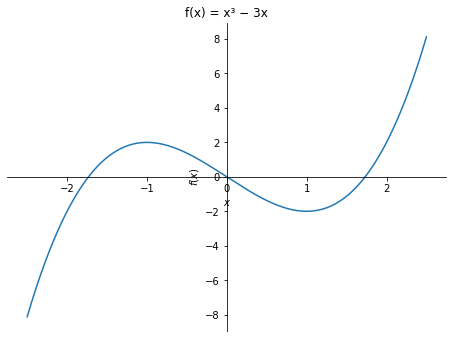

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
plot(x**3 - 3*x, (x, -2.5, 2.5), title='f(x) = x³ − 3x');
```

</details>

#### Aufgabe 2.5

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
plot(x, x**2, x**3, (x, -1.5, 1.5), legend=True);
```

In [ ]:
plot(x, x**2, x**3, (x, -1.5, 1.5), legend=True);

## 3. Lineare Funktionen

#### Steigung, Gerade durch zwei Punkte, Schnittpunkt

Eine lineare Funktion hat die Gleichung f(x) = m·x + c mit der **Steigung** m und dem **y-Achsenabschnitt** c.

- Durch die Punkte (x₁, y₁) und (x₂, y₂): m = (y₂ − y₁)/(x₂ − x₁), danach c aus y₁ = m·x₁ + c.
- **Nullstelle:** `solve(m*x + c, x)`
- **Schnittpunkt** zweier Geraden: Funktionsterme gleichsetzen.
- Zwei Geraden sind **parallel**, wenn sie dieselbe Steigung haben.

In [ ]:
m = Rational(7 - 1, 4 - 1)
c0 = 1 - m * 1
display(m, c0)
g = m*x + c0
display(g)
display(solve(g, x))
solve(Eq(g, -x + 7), x)

#### Aufgabe 3.1

Bestimme die Steigung der Geraden durch die Punkte (2, 3) und (6, 11).

**Erwartete Ausgabe:**

$\displaystyle 2$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
Rational(11 - 3, 6 - 2)
```

</details>

#### Aufgabe 3.2

Bestimme die Gleichung der Geraden durch (−1, 4) und (3, −4). Gib den Term `m·x + c` aus.

**Erwartete Ausgabe:**

$\displaystyle 2 - 2 x$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
m = Rational(-4 - 4, 3 - (-1))
c0 = 4 - m * (-1)
m*x + c0
```

</details>

#### Aufgabe 3.3

Bestimme die Nullstelle von `f(x) = 3x − 7`.

**Erwartete Ausgabe:**

$\displaystyle \left[ \frac{7}{3}\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
solve(3*x - 7, x)
```

</details>

#### Aufgabe 3.4

Bestimme den Schnittpunkt der Geraden `y = 2x + 1` und `y = −x + 7`: Gib die x-Koordinate und den Punkt als Tupel aus.

**Erwartete Ausgabe:**

$\displaystyle 2$

$\displaystyle \left( 2, \  5\right)$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
xs = solve(Eq(2*x + 1, -x + 7), x)[0]
display(xs)
(xs, 2*xs + 1)
```

</details>

#### Aufgabe 3.5

Prüfe, ob die Geraden `y = 3x − 2` und `y = 3x + 5` einen Schnittpunkt haben: Gib die Lösungsmenge der Gleichung aus.

**Erwartete Ausgabe:**

$\displaystyle \emptyset$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
solveset(Eq(3*x - 2, 3*x + 5), x, domain=S.Reals)
```

</details>

#### Aufgabe 3.6

Bestimme die Gleichung der Geraden, die parallel zu `y = −2x + 1` ist und durch den Punkt (3, 4) geht.

**Erwartete Ausgabe:**

$\displaystyle 10 - 2 x$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
c0 = 4 - (-2) * 3
-2*x + c0
```

</details>

#### Aufgabe 3.7

**Taxi:** Ein Taxi kostet 4 € Grundgebühr und 2,20 € pro km. Gib den Funktionsterm für die Kosten aus, berechne die Kosten für 12 km
und die Strecke, die man für 30 € fahren kann.

**Erwartete Ausgabe:**

$\displaystyle \frac{11 x}{5} + 4$

$\displaystyle \frac{152}{5}$

$\displaystyle \left[ \frac{130}{11}\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
k = 4 + Rational('2.2')*x
display(k)
display(k.subs(x, 12))
solve(Eq(k, 30), x)
```

</details>

#### Aufgabe 3.8

Zeichne die Geraden `y = 0,5x + 1` und `y = −2x + 6` für x von −1 bis 4 mit Legende und gib ihren Schnittpunkt als Tupel aus.

**Erwartete Ausgabe:**

$\displaystyle \left( 2, \  2\right)$

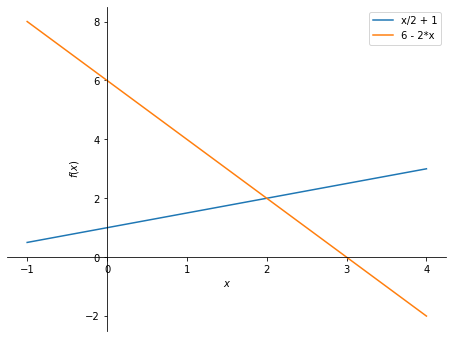

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
g1 = Rational(1, 2)*x + 1
g2 = -2*x + 6
plot(g1, g2, (x, -1, 4), legend=True)
xs = solve(Eq(g1, g2), x)[0]
(xs, g1.subs(x, xs))
```

</details>

#### Aufgabe 3.9

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
m = Rational(2, 4)
display(m * 6)
solve(Eq(m*x + 1, 0), x)
```

In [ ]:
m = Rational(2, 4)
display(m * 6)
solve(Eq(m*x + 1, 0), x)

## 4. Quadratische Funktionen

#### Scheitelpunkt und Scheitelform

f(x) = a·x² + b·x + c hat den **Scheitelpunkt** S(xₛ | yₛ) mit xₛ = −b/(2a) und yₛ = f(xₛ).
Die **Scheitelform** ist f(x) = a(x − xₛ)² + yₛ. Ob man richtig umgeformt hat, prüft man mit `expand()`.

Die **Nullstellen** liefert `solve()`, die **Linearfaktorform** a(x − x₁)(x − x₂) liefert `factor()`.

In [ ]:
def f(x):
    return 2*x**2 - 8*x + 6

xs = Rational(8, 2 * 2)
display(xs, f(xs))
scheitelform = 2*(x - xs)**2 + f(xs)
display(scheitelform)
display(expand(scheitelform) == f(x))
display(solve(f(x), x))
factor(f(x))

#### Die Parameter der Scheitelform

In f(x) = a(x − d)² + e verschiebt d den Graphen nach rechts, e nach oben. a streckt ihn (|a| > 1), staucht ihn (|a| < 1)
oder spiegelt ihn an der x-Achse (a < 0).

In [ ]:
plot(x**2, (x - 2)**2 + 1, -Rational(1, 2)*(x + 1)**2 + 3, (x, -4, 4), ylim=(-3, 8), legend=True);

#### Aufgabe 4.1

Bestimme den Scheitelpunkt von `f(x) = x² − 6x + 5` als Tupel.

**Erwartete Ausgabe:**

$\displaystyle \left( 3, \  -4\right)$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
xs = Rational(6, 2)
(xs, (x**2 - 6*x + 5).subs(x, xs))
```

</details>

#### Aufgabe 4.2

Bestimme den Scheitelpunkt von `f(x) = −2x² + 4x + 1` als Tupel.

**Erwartete Ausgabe:**

$\displaystyle \left( 1, \  3\right)$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
xs = Rational(-4, 2 * -2)
(xs, (-2*x**2 + 4*x + 1).subs(x, xs))
```

</details>

#### Aufgabe 4.3

Prüfe, dass `(x − 3)² − 4` die Scheitelform von `x² − 6x + 5` ist.

**Erwartete Ausgabe:**

```
True
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
expand((x - 3)**2 - 4) == x**2 - 6*x + 5
```

</details>

#### Aufgabe 4.4

Bestimme die Nullstellen von `f(x) = x² − 6x + 5` und gib die Linearfaktorform aus.

**Erwartete Ausgabe:**

$\displaystyle \left[ 1, \  5\right]$

$\displaystyle \left(x - 5\right) \left(x - 1\right)$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(solve(x**2 - 6*x + 5, x))
factor(x**2 - 6*x + 5)
```

</details>

#### Aufgabe 4.5

Gib die Normalform der Parabel mit dem Scheitel S(−1 | 4) und a = −1 aus.

**Erwartete Ausgabe:**

$\displaystyle - x^{2} - 2 x + 3$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
expand(-(x + 1)**2 + 4)
```

</details>

#### Aufgabe 4.6

Gib die Normalform der Parabel mit den Nullstellen −2 und 3 aus, die durch den Punkt (0, 12) geht. Tipp: a(x + 2)(x − 3), a aus dem Punkt bestimmen.

**Erwartete Ausgabe:**

$\displaystyle - 2 x^{2} + 2 x + 12$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
a_wert = solve(Eq(a * (0 + 2) * (0 - 3), 12), a)[0]
expand(a_wert * (x + 2) * (x - 3))
```

</details>

#### Aufgabe 4.7

Zeichne `x² − 6x + 5` und seine Scheitelform `(x − 3)² − 4` für x von 0 bis 6 (die Graphen liegen übereinander).

**Erwartete Ausgabe:**



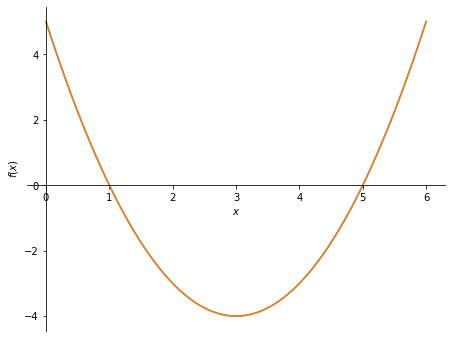

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
plot(x**2 - 6*x + 5, (x - 3)**2 - 4, (x, 0, 6));
```

</details>

#### Aufgabe 4.8

Zeichne die Parabeln `(x − d)²` für d = −2, 0, 2 für x von −5 bis 5 mit Legende.

**Erwartete Ausgabe:**



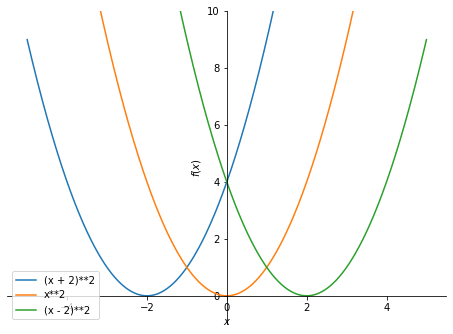

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
plot((x + 2)**2, x**2, (x - 2)**2, (x, -5, 5), ylim=(-1, 10), legend=True);
```

</details>

#### Aufgabe 4.9

**Extremwertaufgabe:** Ein Rechteck hat den Umfang 24 cm. Seine Breite ist x, die Länge 12 − x. Gib den Term für den Flächeninhalt aus,
bestimme die Breite mit dem größten Flächeninhalt (Scheitelstelle) und den größten Flächeninhalt.

**Erwartete Ausgabe:**

$\displaystyle - x^{2} + 12 x$

$\displaystyle 6$

$\displaystyle 36$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
A = expand(x * (12 - x))
display(A)
xs = Rational(-12, 2 * -1)
display(xs)
A.subs(x, xs)
```

</details>

#### Aufgabe 4.10

Ein Ball wird geworfen. Seine Höhe ist `h(t) = −5t² + 20t + 1,5` (t in s, h in m). Gib die größte Höhe aus und den Zeitpunkt, an dem er auf dem
Boden aufkommt (positive Nullstelle, mit `N()` auf 3 Ziffern).

**Erwartete Ausgabe:**

$\displaystyle \frac{43}{2}$

$\displaystyle 4.07$

In [ ]:
t = symbols('t')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
t = symbols('t')
h = -5*t**2 + 20*t + Rational('1.5')
tm = Rational(-20, 2 * -5)
display(h.subs(t, tm))
N(max(solve(h, t)), 3)
```

</details>

#### Aufgabe 4.11

Bestimme mit `maximum()` den größten Wert von `−x² + 4x + 1` auf den reellen Zahlen. Vergleiche mit der Scheitelpunktberechnung.

**Erwartete Ausgabe:**

$\displaystyle 5$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
maximum(-x**2 + 4*x + 1, x, S.Reals)
```

</details>

#### Aufgabe 4.12

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
display(factor(x**2 - 4*x + 4))
display(solve(x**2 - 4*x + 4, x))
minimum(x**2 - 4*x + 4, x, S.Reals)
```

In [ ]:
display(factor(x**2 - 4*x + 4))
display(solve(x**2 - 4*x + 4, x))
minimum(x**2 - 4*x + 4, x, S.Reals)

## 5. Potenz- und Wurzelfunktionen

#### Potenzfunktionen, Symmetrie, Definitions- und Wertemenge

f(x) = xⁿ: Bei **geradem** n ist der Graph **achsensymmetrisch** zur y-Achse (f(−x) = f(x)), bei **ungeradem** n **punktsymmetrisch**
zum Ursprung (f(−x) = −f(x)). Das prüft man mit `simplify(f(-x) - f(x)) == 0` bzw. `simplify(f(-x) + f(x)) == 0`.

Die **Definitionsmenge** (für welche x ist f definiert?) und die **Wertemenge** (welche y kommen vor?) bestimmen
`continuous_domain()` und `function_range()`. Sie müssen extra importiert werden.

In [ ]:
from sympy.calculus.util import continuous_domain, function_range
plot(x**2, x**3, x**4, (x, -1.5, 1.5), ylim=(-3, 3), legend=True)
f = x**3
display(simplify(f.subs(x, -x) + f) == 0)
display(continuous_domain(sqrt(x), x, S.Reals))
display(function_range(x**2, x, S.Reals))
function_range(1 / x, x, S.Reals)

#### Aufgabe 5.1

Zeichne die Graphen von `x⁻¹` und `x⁻²` für x von −3 bis 3 mit der y-Achse von −5 bis 5 und Legende.

**Erwartete Ausgabe:**



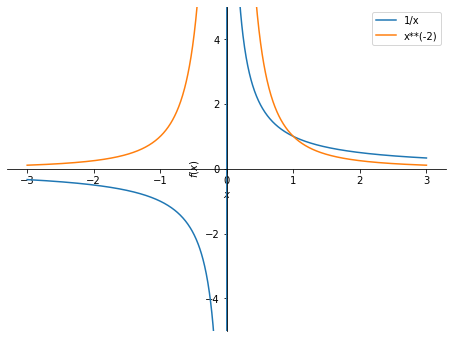

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
plot(x**-1, x**-2, (x, -3, 3), ylim=(-5, 5), legend=True);
```

</details>

#### Aufgabe 5.2

Prüfe, ob `f(x) = x⁴ − 3x²` achsensymmetrisch zur y-Achse ist.

**Erwartete Ausgabe:**

```
True
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = x**4 - 3*x**2
simplify(f.subs(x, -x) - f) == 0
```

</details>

#### Aufgabe 5.3

Prüfe, ob `f(x) = x³ − 2x` punktsymmetrisch zum Ursprung ist.

**Erwartete Ausgabe:**

```
True
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = x**3 - 2*x
simplify(f.subs(x, -x) + f) == 0
```

</details>

#### Aufgabe 5.4

Prüfe, ob `f(x) = x³ + x²` achsensymmetrisch oder punktsymmetrisch ist. Gib beide Prüfungen aus.

**Erwartete Ausgabe:**

```
False
```

```
False
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = x**3 + x**2
display(simplify(f.subs(x, -x) - f) == 0)
simplify(f.subs(x, -x) + f) == 0
```

</details>

#### Aufgabe 5.5

Bestimme die Definitionsmenge von `√(x − 3)`.

**Erwartete Ausgabe:**

$\displaystyle \left[3, \infty\right)$

In [ ]:
from sympy.calculus.util import continuous_domain
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from sympy.calculus.util import continuous_domain
continuous_domain(sqrt(x - 3), x, S.Reals)
```

</details>

#### Aufgabe 5.6

Bestimme die Definitionsmenge von `1/(x² − 4)`.

**Erwartete Ausgabe:**

$\displaystyle \left(-\infty, -2\right) \cup \left(-2, 2\right) \cup \left(2, \infty\right)$

In [ ]:
from sympy.calculus.util import continuous_domain
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from sympy.calculus.util import continuous_domain
continuous_domain(1 / (x**2 - 4), x, S.Reals)
```

</details>

#### Aufgabe 5.7

Bestimme die Wertemenge von `x² − 4x + 1`.

**Erwartete Ausgabe:**

$\displaystyle \left[-3, \infty\right)$

In [ ]:
from sympy.calculus.util import function_range
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from sympy.calculus.util import function_range
function_range(x**2 - 4*x + 1, x, S.Reals)
```

</details>

#### Aufgabe 5.8

Bestimme die Wertemenge von `√x + 2`.

**Erwartete Ausgabe:**

$\displaystyle \left[2, \infty\right)$

In [ ]:
from sympy.calculus.util import function_range
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from sympy.calculus.util import function_range
function_range(sqrt(x) + 2, x, S.Reals)
```

</details>

#### Aufgabe 5.9

Zeichne `√x` und `x²` für x von 0 bis 2 und gib die Schnittstellen aus (`solve(Eq(sqrt(x), x**2), x)`).

**Erwartete Ausgabe:**

$\displaystyle \left[ 0, \  1\right]$

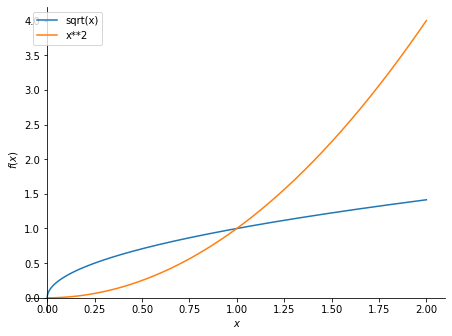

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
plot(sqrt(x), x**2, (x, 0, 2), legend=True)
solve(Eq(sqrt(x), x**2), x)
```

</details>

## 6. Exponentialfunktionen und Wachstum

#### f(x) = c · aˣ + d

- Für a > 1 wächst der Graph (**exponentielles Wachstum**), für 0 < a < 1 fällt er (**exponentielle Abnahme**).
- c ist der Funktionswert bei x = 0 (ohne d), d verschiebt den Graphen nach oben. Die Gerade y = d ist eine **Asymptote**.
- Das Verhalten für sehr große bzw. sehr kleine x bestimmt man mit dem **Grenzwert** `limit(f, x, oo)` bzw. `limit(f, x, -oo)`.
  `oo` (zwei kleine o) steht in sympy für ∞.

In [ ]:
f = 3 * Rational(1, 2)**x + 1
plot(2**x, f, (x, -3, 4), ylim=(-1, 10), legend=True)
display(limit(f, x, oo))
limit(2**x, x, -oo)

#### Aufgabe 6.1

Zeichne `2ˣ`, `3ˣ` und `0,5ˣ` für x von −3 bis 3 mit der y-Achse von 0 bis 10 und Legende.

**Erwartete Ausgabe:**



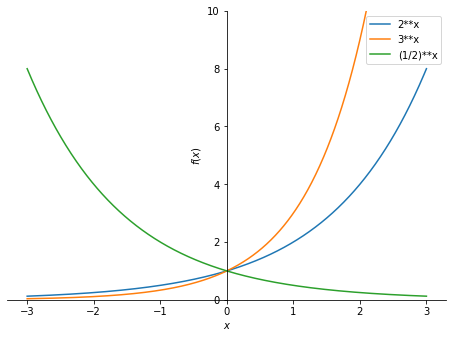

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
plot(2**x, 3**x, Rational(1, 2)**x, (x, -3, 3), ylim=(0, 10), legend=True);
```

</details>

#### Aufgabe 6.2

Bestimme die Grenzwerte von `f(x) = 5 · 0,8ˣ + 2` für x → ∞ und x → −∞.

**Erwartete Ausgabe:**

$\displaystyle 2$

$\displaystyle \infty$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = 5 * Rational('0.8')**x + 2
display(limit(f, x, oo))
limit(f, x, -oo)
```

</details>

#### Aufgabe 6.3

Eine Population hat 200 Tiere und wächst um 15 % pro Jahr. Gib den Funktionsterm aus, die Größe nach 10 Jahren (ganzzahlig gerundet mit `round(N(...))`)
und die Verdopplungszeit mit 4 Ziffern.

**Erwartete Ausgabe:**

$\displaystyle 200 \left(\frac{23}{20}\right)^{x}$

$\displaystyle 809$

$\displaystyle 4.959$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
P = 200 * Rational('1.15')**x
display(P)
display(round(N(P.subs(x, 10))))
N(solve(Eq(Rational('1.15')**x, 2), x)[0], 4)
```

</details>

#### Aufgabe 6.4

Ein Medikament wird abgebaut: Von 400 mg sind nach jeder Stunde nur noch 80 % vorhanden. Gib die Halbwertszeit mit 4 Ziffern aus
und zeichne den Verlauf für die ersten 12 Stunden.

**Erwartete Ausgabe:**

$\displaystyle 3.106$

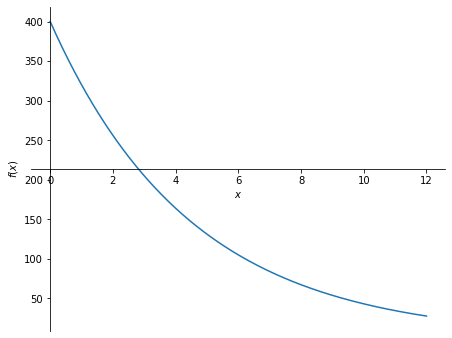

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
M = 400 * Rational('0.8')**x
plot(M, (x, 0, 12))
N(solve(Eq(Rational('0.8')**x, Rational(1, 2)), x)[0], 4)
```

</details>

#### Aufgabe 6.5

Bestimme `c` und `a` für eine Exponentialfunktion `f(x) = c · aˣ` durch die Punkte (0, 3) und (2, 12). Lege `a` positiv an.

**Erwartete Ausgabe:**

$\displaystyle 3 \cdot 2^{x}$

In [ ]:
a = symbols('a', positive=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
a = symbols('a', positive=True)
c0 = 3
a_wert = solve(Eq(c0 * a**2, 12), a)[0]
c0 * a_wert**x
```

</details>

#### Aufgabe 6.6

Ein Tee kühlt ab: `T(x) = 20 + 70 · 0,9ˣ` (x in Minuten). Gib die Temperatur, der sich der Tee annähert (Grenzwert für x → ∞), und den Zeitpunkt aus,
an dem er 40 °C hat (mit 4 Ziffern).

**Erwartete Ausgabe:**

$\displaystyle 20$

$\displaystyle 11.89$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
T = 20 + 70 * Rational('0.9')**x
display(limit(T, x, oo))
N(solve(Eq(T, 40), x)[0], 4)
```

</details>

#### Aufgabe 6.7

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
display(limit(2**(-x), x, oo))
display(limit(1 / x, x, oo))
limit(x**2, x, -oo)
```

In [ ]:
display(limit(2**(-x), x, oo))
display(limit(1 / x, x, oo))
limit(x**2, x, -oo)

## 7. Ganzrationale Funktionen

#### Nullstellen mit Vielfachheit und Verhalten im Unendlichen

Eine **ganzrationale Funktion** (Polynomfunktion) ist eine Summe von Potenzen von x, z. B. f(x) = x³ − 3x + 2.

- `degree(f, x)` ist der **Grad** (höchste Potenz).
- `roots(f, x)` gibt die Nullstellen mit ihrer **Vielfachheit** als Dictionary zurück: {Nullstelle: Vielfachheit}.
  An einer **doppelten** Nullstelle berührt der Graph die x-Achse, an einer einfachen schneidet er sie.
- `factor(f)` zeigt die faktorisierte Form.
- Für x → ±∞ bestimmt der Summand mit der höchsten Potenz das Verhalten.

In [ ]:
f = x**3 - 3*x + 2
display(degree(f, x))
display(roots(f, x))
display(factor(f))
display(limit(f, x, oo), limit(f, x, -oo))
plot(f, (x, -3, 2.5), ylim=(-5, 8));

#### Aufgabe 7.1

Gib Grad, Nullstellen mit Vielfachheit und faktorisierte Form von `f(x) = x³ − x² − 4x + 4` aus.

**Erwartete Ausgabe:**

$\displaystyle 3$

$\displaystyle \left\{ -2 : 1, \  1 : 1, \  2 : 1\right\}$

$\displaystyle \left(x - 2\right) \left(x - 1\right) \left(x + 2\right)$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = x**3 - x**2 - 4*x + 4
display(degree(f, x))
display(roots(f, x))
factor(f)
```

</details>

#### Aufgabe 7.2

Gib die Nullstellen mit Vielfachheit von `f(x) = x⁴ − 2x³ + x²` aus.

**Erwartete Ausgabe:**

$\displaystyle \left\{ 0 : 2, \  1 : 2\right\}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
roots(x**4 - 2*x**3 + x**2, x)
```

</details>

#### Aufgabe 7.3

Zeichne `f(x) = x⁴ − 2x³ + x²` für x von −0,7 bis 1,7 und achte auf die doppelten Nullstellen.

**Erwartete Ausgabe:**



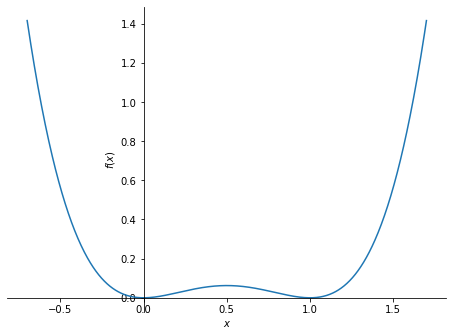

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
plot(x**4 - 2*x**3 + x**2, (x, -0.7, 1.7));
```

</details>

#### Aufgabe 7.4

Gib eine ganzrationale Funktion 3. Grades mit den Nullstellen −1, 2 und 4 und dem Faktor 1 ausmultipliziert aus.

**Erwartete Ausgabe:**

$\displaystyle x^{3} - 5 x^{2} + 2 x + 8$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
expand((x + 1) * (x - 2) * (x - 4))
```

</details>

#### Aufgabe 7.5

Gib eine Funktion 4. Grades aus, die bei 0 eine doppelte Nullstelle und bei ±3 einfache Nullstellen hat (Faktor −1), ausmultipliziert.

**Erwartete Ausgabe:**

$\displaystyle - x^{4} + 9 x^{2}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
expand(-x**2 * (x - 3) * (x + 3))
```

</details>

#### Aufgabe 7.6

Bestimme die Grenzwerte von `f(x) = −2x³ + 5x² + 1` für x → ∞ und x → −∞.

**Erwartete Ausgabe:**

$\displaystyle -\infty$

$\displaystyle \infty$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = -2*x**3 + 5*x**2 + 1
display(limit(f, x, oo))
limit(f, x, -oo)
```

</details>

#### Aufgabe 7.7

Bestimme die reellen Nullstellen von `x³ − 2x − 1` exakt (`solveset`) und als Dezimalzahlen mit 4 Ziffern.

**Erwartete Ausgabe:**

$\displaystyle \left\{-1, \frac{1}{2} - \frac{\sqrt{5}}{2}, \frac{1}{2} + \frac{\sqrt{5}}{2}\right\}$

$\displaystyle \left[ -1.0, \  -0.618, \  1.618\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
l = solveset(x**3 - 2*x - 1, x, domain=S.Reals)
display(l)
[N(w, 4) for w in l]
```

</details>

#### Aufgabe 7.8

Bestimme die Nullstellen von `f(x) = x³ − 2x² − 5x + 6` und prüfe die Symmetrie (beide Prüfungen). Zeichne den Graphen für x von −3 bis 4.

**Erwartete Ausgabe:**

$\displaystyle \left\{ -2 : 1, \  1 : 1, \  3 : 1\right\}$

```
False
```

```
False
```

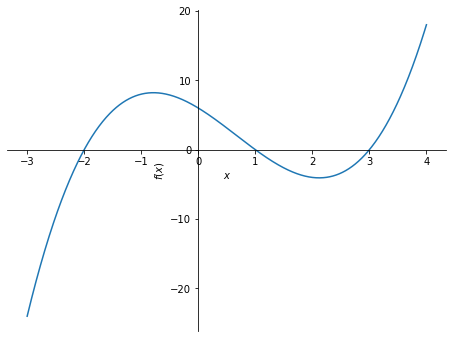

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = x**3 - 2*x**2 - 5*x + 6
display(roots(f, x))
display(simplify(f.subs(x, -x) - f) == 0, simplify(f.subs(x, -x) + f) == 0)
plot(f, (x, -3, 4));
```

</details>

#### Aufgabe 7.9

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
display(roots((x - 1)**2 * (x + 2), x))
display(degree(x**5 - x, x))
factor(x**3 - x**2)
```

In [ ]:
display(roots((x - 1)**2 * (x + 2), x))
display(degree(x**5 - x, x))
factor(x**3 - x**2)

## 8. Sinusfunktionen

#### Bogenmaß und exakte Werte

In sympy rechnen `sin`, `cos` und `tan` im **Bogenmaß**: Der Vollwinkel 360° ist 2π. `rad(90)` rechnet 90° in Bogenmaß um (π/2),
`deg(pi)` umgekehrt. Für besondere Winkel kennt sympy **exakte** Werte: sin(π/6) = 1/2, sin(π/4) = √2/2.

In [ ]:
display(rad(90), deg(pi / 3))
display(sin(pi / 6), sin(pi / 4), cos(pi / 3))
N(sin(1), 5)

#### f(x) = a · sin(b(x − c)) + d

- a ist die **Amplitude** (Streckung in y-Richtung),
- die **Periode** ist 2π/b (`periodicity(f, x)` berechnet sie),
- c verschiebt nach rechts, d nach oben.

In [ ]:
display(periodicity(sin(3*x), x))
plot(sin(x), 2*sin(x), sin(2*x), (x, 0, 2*pi), legend=True);

#### Aufgabe 8.1

Rechne 45°, 120° und 270° in Bogenmaß um.

**Erwartete Ausgabe:**

$\displaystyle \frac{\pi}{4}$

$\displaystyle \frac{2 \pi}{3}$

$\displaystyle \frac{3 \pi}{2}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(rad(45), rad(120), rad(270))
```

</details>

#### Aufgabe 8.2

Gib die exakten Werte von `cos(π/6)`, `tan(π/4)` und `sin(2π/3)` aus.

**Erwartete Ausgabe:**

$\displaystyle \frac{\sqrt{3}}{2}$

$\displaystyle 1$

$\displaystyle \frac{\sqrt{3}}{2}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(cos(pi / 6), tan(pi / 4), sin(2*pi / 3))
```

</details>

#### Aufgabe 8.3

Gib `sin(37°)` mit 4 Ziffern aus.

**Erwartete Ausgabe:**

$\displaystyle 0.6018$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
N(sin(rad(37)), 4)
```

</details>

#### Aufgabe 8.4

Bestimme die Periode von `sin(4x)`, `cos(x/2)` und `3 sin(πx)`.

**Erwartete Ausgabe:**

$\displaystyle \frac{\pi}{2}$

$\displaystyle 4 \pi$

$\displaystyle 2$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(periodicity(sin(4*x), x), periodicity(cos(x / 2), x), periodicity(3*sin(pi*x), x))
```

</details>

#### Aufgabe 8.5

Zeichne `sin(x)` und `cos(x)` für x von −π bis 2π mit Legende.

**Erwartete Ausgabe:**



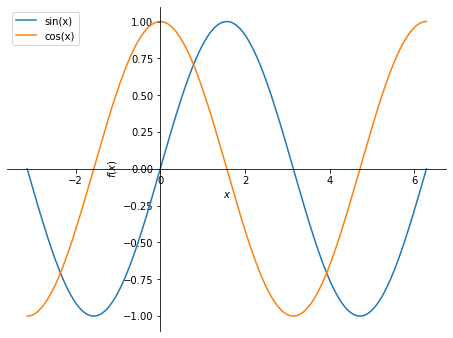

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
plot(sin(x), cos(x), (x, -pi, 2*pi), legend=True);
```

</details>

#### Aufgabe 8.6

Zeichne `2 sin(x − π/2) + 1` für x von 0 bis 2π.

**Erwartete Ausgabe:**



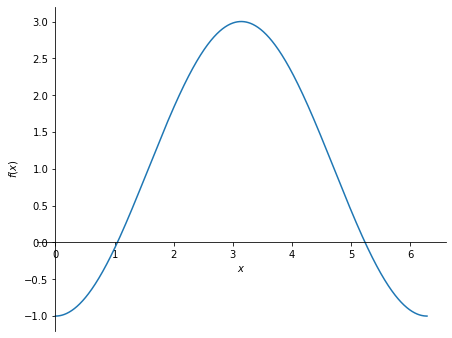

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
plot(2*sin(x - pi / 2) + 1, (x, 0, 2*pi));
```

</details>

#### Aufgabe 8.7

Prüfe, dass `sin(x + π/2) = cos(x)` gilt.

**Erwartete Ausgabe:**

```
True
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
simplify(sin(x + pi / 2) - cos(x)) == 0
```

</details>

#### Aufgabe 8.8

Bestimme alle Lösungen von `sin(x) = 1/2` im Intervall [0, 2π].

**Erwartete Ausgabe:**

$\displaystyle \left\{\frac{\pi}{6}, \frac{5 \pi}{6}\right\}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
solveset(Eq(sin(x), Rational(1, 2)), x, domain=Interval(0, 2*pi))
```

</details>

#### Aufgabe 8.9

**Tageslänge:** In einer Stadt ist die Tageslänge (in Stunden) am Tag x des Jahres etwa `12 + 4,5 · sin(2π/365 · (x − 80))`.
Gib die Periode aus, zeichne den Verlauf für ein Jahr und gib die Tageslänge am Tag 172 (21. Juni) mit 3 Ziffern aus.

**Erwartete Ausgabe:**

$\displaystyle 365$

$\displaystyle 16.5$

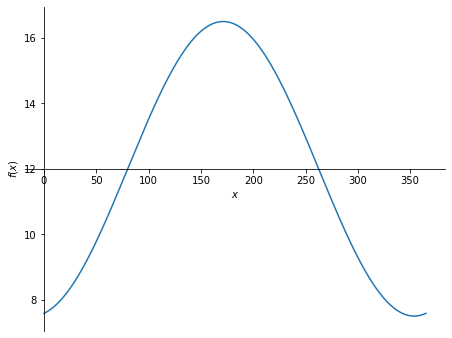

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
L = 12 + Rational('4.5') * sin(2*pi / 365 * (x - 80))
display(periodicity(L, x))
plot(L, (x, 0, 365))
N(L.subs(x, 172), 3)
```

</details>

#### Aufgabe 8.10

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
display(sin(pi), cos(pi), sin(pi / 2))
display(periodicity(sin(x) + cos(x), x))
rad(180)
```

In [ ]:
display(sin(pi), cos(pi), sin(pi / 2))
display(periodicity(sin(x) + cos(x), x))
rad(180)

## 9. Gemischte Übungen

#### Aufgabe 9.1

Bestimme die Schnittpunkte der Parabel `y = x² − 2` mit der Geraden `y = x` als Liste von Punkten und zeichne beide für x von −3 bis 3.

**Erwartete Ausgabe:**

$\displaystyle \left[ \left( -1, \  -1\right), \  \left( 2, \  2\right)\right]$

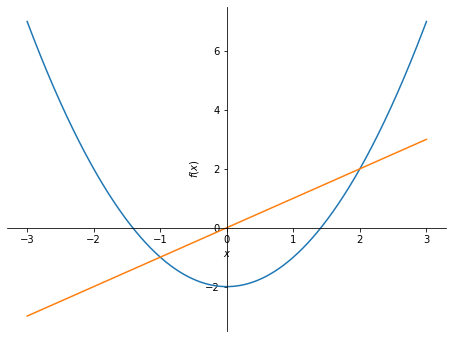

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
plot(x**2 - 2, x, (x, -3, 3))
[(w, w) for w in solve(Eq(x**2 - 2, x), x)]
```

</details>

#### Aufgabe 9.2

Für welche Werte von `k` berührt die Gerade `y = k` die Parabel `y = x² − 4x + 7` genau in einem Punkt? Das ist der y-Wert des Scheitels.
Berechne ihn mit `minimum()`.

**Erwartete Ausgabe:**

$\displaystyle 3$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
minimum(x**2 - 4*x + 7, x, S.Reals)
```

</details>

#### Aufgabe 9.3

Ein Sparkonto mit 1000 € wird mit 2 % verzinst, ein zweites mit 800 € mit 4 %. Ab welchem Jahr hat das zweite mehr Geld? Zeichne beide
Verläufe für 0 bis 20 Jahre und gib die Schnittstelle mit `nsolve()` (Startwert 10) aus.

**Erwartete Ausgabe:**

$\displaystyle 11.4915318098978$

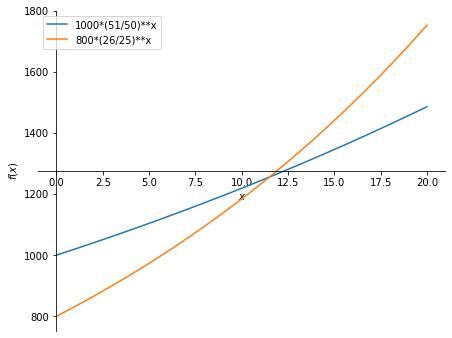

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
k1 = 1000 * Rational('1.02')**x
k2 = 800 * Rational('1.04')**x
plot(k1, k2, (x, 0, 20), legend=True)
nsolve(Eq(k1, k2), x, 10)
```

</details>

#### Aufgabe 9.4

Gib für `f(x) = x³ − 6x² + 9x` die Nullstellen mit Vielfachheit, das Verhalten für x → ±∞ und den Graphen für x von −0,5 bis 4,5 aus.

**Erwartete Ausgabe:**

$\displaystyle \left\{ 0 : 1, \  3 : 2\right\}$

$\displaystyle \infty$

$\displaystyle -\infty$

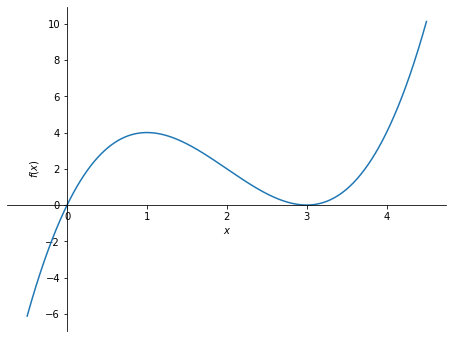

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = x**3 - 6*x**2 + 9*x
display(roots(f, x))
display(limit(f, x, oo), limit(f, x, -oo))
plot(f, (x, -0.5, 4.5));
```

</details>

#### Aufgabe 9.5

Die Parabel `y = ax² + bx + c` geht durch die Punkte (−1, 6), (1, 2) und (2, 3). Bestimme a, b und c und gib den Scheitelpunkt als Tupel aus.

**Erwartete Ausgabe:**

$\displaystyle x^{2} - 2 x + 3$

$\displaystyle \left( 1, \  2\right)$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
l = solve([Eq(a - b + c, 6), Eq(a + b + c, 2), Eq(4*a + 2*b + c, 3)], [a, b, c])
f = l[a]*x**2 + l[b]*x + l[c]
display(f)
xs = -l[b] / (2 * l[a])
(xs, f.subs(x, xs))
```

</details>